# RouteRanker – Module 4: Data Preprocessing
**Goal:** turn the Module-2 route features into a clean, consistent table that the planned *distance-based* models (KMeans, DBSCAN) can use – handling missing values, encoding categories, scaling, and a leak-free training/validation split.

**Guidelines followed:** the raw and Module-2 files are never overwritten; every decision is explained; **no passenger counts and no 'overcrowded / underutilised' labels are created** – GTFS has no passenger data, so no valid supervised target exists. Scheduled trips describe planned service, not demand.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src import preprocessing as pp
pd.set_option("display.max_columns", 40, "display.width", 200)
raw = pp.load_features("data/processed/all_cities_route_features.csv")   # Module-2 output, read-only
print(raw.shape)
raw.head(3)

(14097, 48)


,city,route_id,route_name,route_type,n_trips,median_stops_per_trip,avg_trip_duration_min,median_trip_duration_min,n_service_ids,trips_from_frequency,has_time_backwards_trip,first_departure_h,last_departure_h,n_directions,service_span_h,n_active_hours,peak_hour,peak_hour_trips,trips_per_active_hour,trips_morning,...,trips_friday,trips_saturday,trips_sunday,avg_trips_per_weekday,avg_trips_per_weekend_day,weekend_to_weekday_ratio,length_km_stops,length_km_shape,length_km,length_method,n_unique_stops,stops_per_km,avg_speed_kmh,speed_implausible,overlap_partner,max_stop_overlap,overlap_share_of_route,overlap_partner_name,mean_routes_per_stop,sparse_schedule
0,ahmedabad,AMC_1790,101sh,3,5,44.0,77.000000,80.0,1,0,False,7.000000,18.666667,1.0,11.666667,5,7,1,1.0,2,...,5,5,5,5.0,5.0,1.0,44.528508,NaN,44.528508,"stop coordinates (straight-line, approximate)",44,0.988131,33.396381,False,AMC_2228,0.148936,0.318182,16,20.068182,False
1,ahmedabad,AMC_1791,101sh,3,5,44.0,72.000000,80.0,1,0,False,6.333333,17.250000,1.0,10.916667,5,6,1,1.0,3,...,5,5,5,5.0,5.0,1.0,44.528508,NaN,44.528508,"stop coordinates (straight-line, approximate)",44,0.988131,33.396381,False,AMC_2228,0.148936,0.318182,16,20.068182,False
2,ahmedabad,AMC_1798,103,3,14,71.0,102.857143,105.0,1,0,False,6.583333,19.666667,1.0,13.083333,14,6,1,1.0,6,...,14,14,14,14.0,14.0,1.0,22.365567,NaN,22.365567,"stop coordinates (straight-line, approximate)",71,3.174523,12.780324,False,AMC_2914,0.408451,0.408451,90sh,45.619718,False


## 1. Inspect structure, data types, missing values and duplicates

In [2]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique()})
display(info[info.missing > 0])
print("duplicate rows:", raw.duplicated().sum(), "| duplicate (city, route_id):", raw.duplicated(["city", "route_id"]).sum())
raw.groupby("city").size().to_frame("routes").T

,dtype,missing,unique
n_directions,float64,2964,2
median_headway_min,float64,2247,671
length_km_shape,float64,8901,5101
overlap_partner,str,17,7912
overlap_partner_name,str,17,7282


duplicate rows: 0 | duplicate (city, route_id): 0


city,ahmedabad,bengaluru,chennai,delhi,hyderabad,kochi,pune
routes,972,4416,3934,2964,1031,465,315


Only a few columns have missing values. Whether they matter depends on whether they are model features, so the next step identifies the features first.

## 2. Numerical and categorical features relevant for KMeans / DBSCAN

In [3]:
print("numerical candidates:", pp.NUMERIC)
print("categorical features :", pp.CATEGORICAL)
print("identifiers (kept beside the features, never inside them):", pp.ID_COLS)

numerical candidates: ['n_trips', 'n_unique_stops', 'median_stops_per_trip', 'length_km', 'service_span_h', 'n_active_hours', 'trips_per_active_hour', 'median_headway_min', 'avg_trip_duration_min', 'stops_per_km', 'avg_speed_kmh', 'max_stop_overlap', 'mean_routes_per_stop', 'weekend_to_weekday_ratio', 'share_morning', 'share_afternoon', 'share_evening']
categorical features : ['length_method', 'peak_period']
identifiers (kept beside the features, never inside them): ['city', 'route_id', 'route_name']


`route_id`, `route_name` and `city` are identifiers/groups, not measurements. `city` is deliberately **not** a feature so that clusters do not simply reproduce the city. Counts, lengths, times, shares and overlaps are numerical; `length_method` and the period of the busiest hour are categorical (unordered).

## 3. Derived columns
Period shares (trips in a period ÷ all trips), the busiest period (recomputed from `peak_hour` with the Module-2 time rules) and invalid-speed handling. Nothing is invented – everything comes from existing columns.

In [4]:
d = pp.add_derived(raw)
d[["city", "route_name", "n_trips", "trips_morning", "share_morning", "share_afternoon", "share_evening", "share_night", "peak_hour", "peak_period"]].head()

,city,route_name,n_trips,trips_morning,share_morning,share_afternoon,share_evening,share_night,peak_hour,peak_period
0,ahmedabad,101sh,5,2,0.400000,0.400000,0.200000,0.00,7,morning
1,ahmedabad,101sh,5,3,0.600000,0.200000,0.200000,0.00,6,morning
2,ahmedabad,103,14,6,0.428571,0.357143,0.214286,0.00,6,morning
3,ahmedabad,103,8,4,0.500000,0.125000,0.375000,0.00,8,morning
4,ahmedabad,103,4,0,0.000000,0.000000,0.250000,0.75,20,evening


The four shares add up to 1, so `share_night` is implied by the other three and is left out of the feature list (it would only repeat information).

## 4. Missing values – investigate first, then decide
### 4a. `median_headway_min`

In [5]:
h = d.median_headway_min.isna()
ev = pd.DataFrame({"routes": [int((d.n_trips <= 1).sum()), int((d.n_trips >= 2).sum())],
                   "missing_headway": [int(h[d.n_trips <= 1].sum()), int(h[d.n_trips >= 2].sum())]}, index=["routes with 1 trip", "routes with 2+ trips"])
ev["share_missing_%"] = (100 * ev.missing_headway / ev.routes).round(1)
ev

,routes,missing_headway,share_missing_%
routes with 1 trip,2238,2238,100.0
routes with 2+ trips,11859,9,0.1


**Reading:** every missing headway belongs to a route with exactly one scheduled trip. With one departure there is no gap between two departures, so headway is *undefined in the source* – it cannot be recovered from GTFS, and it is **not zero** (zero would mean a bus every 0 minutes). Decision: median imputation (from the training data) **plus** a 0/1 indicator column, so the model can still tell these routes apart.

### 4b. Invalid scheduled speed

In [6]:
sp = raw.loc[raw.city != "hyderabad", "avg_speed_kmh"]
print("below 3 km/h:", int((sp < 3).sum()), "| above 80 km/h:", int((sp > 80).sum()), "| total routes:", len(sp))
d[d.speed_invalid == 1].groupby("city").size().to_frame("invalid_speed_routes")

below 3 km/h: 51 | above 80 km/h: 70 | total routes: 13066


,invalid_speed_routes
city,
ahmedabad,27
bengaluru,92
hyderabad,779
pune,2


Scheduled speed = estimated length ÷ scheduled duration. Below 3 or above 80 km/h no bus timetable is plausible, so the length (a straight-line estimate in many feeds) or the timetable is unreliable. The inputs come from the source, so the speed is not recoverable. Decision: set the impossible value to missing, then median-impute with an indicator – the route stays in the data with all its other valid features.

## 5. Non-comparable feeds
Module 3 found that Hyderabad's 'trips' look like whole vehicle duties. The data shows it:

In [7]:
g = raw.groupby("city").agg(routes=("route_id", "size"), median_trip_duration_min=("median_trip_duration_min", "median"),
                           share_routes_median_trip_over_8h=("median_trip_duration_min", lambda s: round((s > 480).mean(), 2)))
g

,routes,median_trip_duration_min,share_routes_median_trip_over_8h
city,,,
ahmedabad,972,65.000000,0.01
bengaluru,4416,65.000000,0.00
chennai,3934,43.000000,0.00
delhi,2964,87.258333,0.00
hyderabad,1031,827.833333,0.71
kochi,465,64.841667,0.00
pune,315,62.316667,0.00


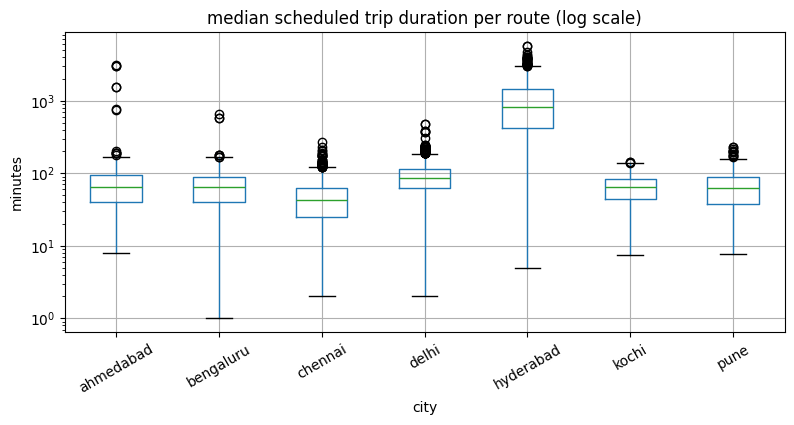

In [8]:
raw.boxplot(column="median_trip_duration_min", by="city", figsize=(9, 4), rot=30); plt.yscale("log")
plt.title("median scheduled trip duration per route (log scale)"); plt.suptitle(""); plt.ylabel("minutes"); plt.show()

**Reading:** in Hyderabad most routes have a median trip longer than 8 hours, unlike the other cities, so `n_trips`, headway, duration and speed do not mean the same there. Putting them into one distance space with single-run trips would distort KMeans/DBSCAN. Decision: **exclude Hyderabad from the pooled modelling set – not delete it**: it stays in Module 2 and in `excluded_routes.csv`, and `python run_module4.py --include-all` keeps it. This is open for the mentor to confirm.

In [9]:
d, ex = pp.split_exclusions(d)
print("modelled routes:", len(d), "| excluded:", len(ex))
pp.missing_report(d, pp.NUMERIC)

modelled routes: 13066 | excluded: 1031


,column,missing,pct,worst_city,worst_city_pct
0,median_headway_min,2102,16.09,bengaluru,23.6
1,avg_speed_kmh,121,0.93,ahmedabad,2.8


## 6. Training / validation split (80:20)
Routes with the same name in a city (up/down/variant patterns of one bus line) look almost identical, so they are kept on the same side – otherwise validation would be too optimistic.

In [10]:
tr, va = pp.train_validation_split(d, test_size=0.2, seed=42)
print("train:", len(tr), "validation:", len(va))
bal = pd.concat([tr.city.value_counts(normalize=True).rename("train"), va.city.value_counts(normalize=True).rename("validation")], axis=1).round(3)
bal.T

train: 10466 validation: 2600


city,bengaluru,chennai,delhi,ahmedabad,kochi,pune
train,0.338,0.307,0.225,0.071,0.036,0.023
validation,0.339,0.279,0.235,0.086,0.033,0.027


In [11]:
overlap = set(tr.city + "|" + tr.route_name) & set(va.city + "|" + va.route_name)
print("bus lines present on both sides of the split:", len(overlap))

bus lines present on both sides of the split: 0


## 7. Fit preprocessing on the training routes only

In [12]:
P = pp.RoutePreprocessor().fit(tr)
print("near-constant features dropped:", P.dropped_constant)
print("features with a missing-value indicator:", [c for c in P.has_missing if c in P.num_final])
print("pairs correlated above", pp.CORR_LIMIT, ":", P.corr_pairs or "none")
sk = P.skew_before.round(2).to_frame("skewness (train)"); sk["log1p applied"] = sk.index.isin(P.log_cols)
sk

near-constant features dropped: ['weekend_to_weekday_ratio']
features with a missing-value indicator: ['median_headway_min', 'avg_speed_kmh']
pairs correlated above 0.95 : none


,skewness (train),log1p applied
n_trips,3.72,True
n_unique_stops,1.38,True
median_stops_per_trip,0.58,False
length_km,11.73,True
service_span_h,-0.20,False
n_active_hours,0.73,False
trips_per_active_hour,3.58,True
median_headway_min,2.68,True
avg_trip_duration_min,26.75,True
stops_per_km,0.96,False


**Why these methods**
* **Median imputation** – robust to the heavy right skew of headways and speeds.
* **log1p** for features with skewness above 1 – counts and lengths have a few extreme routes (Module 3).
* **Standardisation (z-score)** – KMeans and DBSCAN use Euclidean distance, so a feature with large numbers would dominate. Min-max was not used because extreme routes would squeeze everything else into a tiny range, and DBSCAN's distance threshold depends on the spread.
* **One-hot encoding** for `length_method` and `peak_period` – the labels have no order, so label encoding would invent distances between them.
* Everything learned here (medians, skewness decisions, means, standard deviations, categories) comes from the **training** routes only.

## 8. Transform both sets and verify

In [13]:
Xtr, Xva = P.transform(tr), P.transform(va)
print("train:", Xtr.shape, "validation:", Xva.shape)
print("missing values  train/validation:", int(Xtr.isna().sum().sum()), "/", int(Xva.isna().sum().sum()))
print("infinite values train/validation:", int(np.isinf(Xtr.values).sum()), "/", int(np.isinf(Xva.values).sum()))
Xtr[P.num_final].describe().loc[["mean", "std"]].round(2).T.head(8)

train: (10466, 25) validation: (2600, 25)
missing values  train/validation: 0 / 0
infinite values train/validation: 0 / 0


,mean,std
n_trips,-0.0,1.0
n_unique_stops,-0.0,1.0
median_stops_per_trip,-0.0,1.0
length_km,0.0,1.0
service_span_h,0.0,1.0
n_active_hours,0.0,1.0
trips_per_active_hour,-0.0,1.0
median_headway_min,-0.0,1.0


Training means are 0 and standard deviations 1 by construction. The validation set uses the **training** mean and standard deviation, so its values are close to – not exactly – 0 and 1 (this is correct and avoids leakage).

In [14]:
Xva[P.num_final].describe().loc[["mean", "std"]].round(2).T.head(8)

,mean,std
n_trips,-0.01,0.98
n_unique_stops,0.02,1.00
median_stops_per_trip,0.03,1.03
length_km,0.02,0.99
service_span_h,-0.00,0.98
n_active_hours,-0.01,0.97
trips_per_active_hour,-0.03,0.97
median_headway_min,-0.01,0.97


In [15]:
Xtr[[c for c in Xtr.columns if "__" in c]].head()

,length_method__shapes.txt,length_method__stop coordinates (shape failed sanity check),"length_method__stop coordinates (straight-line, approximate)",peak_period__afternoon,peak_period__evening,peak_period__morning,peak_period__night
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0


One-hot columns hold 0/1: one column per category of `length_method` and `peak_period`.

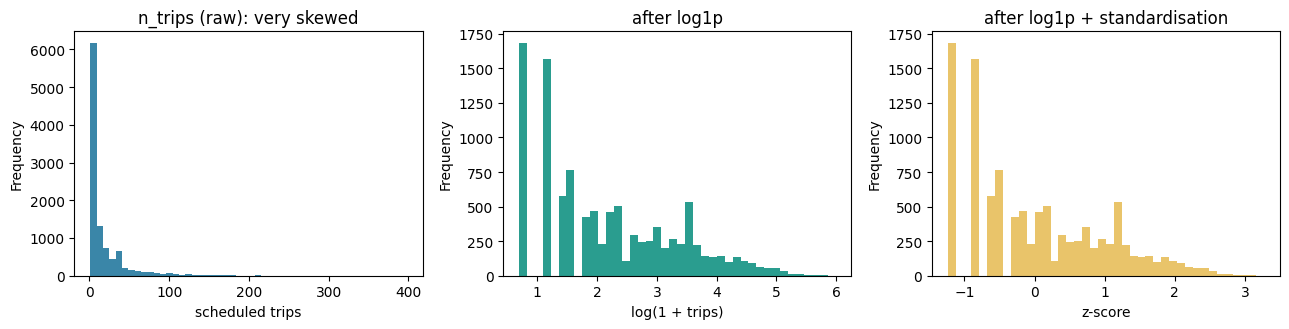

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
tr.n_trips.plot.hist(bins=50, ax=ax[0], color="#3a86a8"); ax[0].set_title("n_trips (raw): very skewed"); ax[0].set_xlabel("scheduled trips")
np.log1p(tr.n_trips).plot.hist(bins=40, ax=ax[1], color="#2a9d8f"); ax[1].set_title("after log1p"); ax[1].set_xlabel("log(1 + trips)")
Xtr.n_trips.plot.hist(bins=40, ax=ax[2], color="#e9c46a"); ax[2].set_title("after log1p + standardisation"); ax[2].set_xlabel("z-score")
plt.tight_layout(); plt.show()

**What it shows:** raw trip counts are dominated by a few routes with hundreds of trips; log1p makes the distribution much more even, and standardisation puts it on the same scale as every other feature.

## 9. Save the processed data and the written reports
The runner writes the CSVs, the fitted preprocessor and the Markdown reports (it repeats exactly the steps above).

In [17]:
import run_module4
run_module4.main()
sorted(os.listdir("data/processed/module4"))

done: train 10466 validation 2600 features 25 excluded 1031 | sanity silhouette 0.17/0.15


['excluded_routes.csv',
 'feature_list.csv',
 'preprocessor.joblib',
 'train_preprocessed.csv',
 'validation_preprocessed.csv']

In [18]:
pd.read_csv("data/processed/module4/feature_list.csv")

,feature,treatment
0,median_headway_min_was_missing,"missing/invalid indicator (0/1, unscaled)"
1,avg_speed_kmh_was_missing,"missing/invalid indicator (0/1, unscaled)"
2,n_trips,log1p + standardised
3,n_unique_stops,log1p + standardised
4,median_stops_per_trip,standardised
5,length_km,log1p + standardised
6,service_span_h,standardised
7,n_active_hours,standardised
8,trips_per_active_hour,log1p + standardised
9,median_headway_min,log1p + standardised


## 10. Is the data ready for the next module?
* No missing or infinite values; all features are numeric; scales are comparable; identifiers are kept separate.
* **No supervised target** was created: classification would need real passenger or performance labels, which GTFS does not contain. KMeans and DBSCAN do not need a target.
* A quick sanity run (reported in `reports/module4_split_and_evaluation_strategy.md`) confirms that KMeans can use the tables; it is **not** a Module 5 result and says nothing about route quality.

**Assumptions and limitations** (details in `reports/module4_assumptions_limitations.md`): speed limits 3–80 km/h and the skew/correlation thresholds are rules of thumb; Hyderabad's exclusion is a judgement for the mentor to confirm; features are scheduled values, several feeds are community-made or old, and clusters will group routes by similar scheduled service – not by 'good' or 'bad' performance.